In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:


# Load datasets

customers = pd.read_csv("olist_customers_dataset.csv")

orders = pd.read_csv("olist_orders_dataset.csv")

order_items = pd.read_csv("olist_order_items_dataset.csv")

products = pd.read_csv("olist_products_dataset.csv")

payments = pd.read_csv("olist_order_payments_dataset.csv")

reviews = pd.read_csv("olist_order_reviews_dataset.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [4]:
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Order Items: (112650, 7)
Products: (32951, 9)
Payments: (103886, 5)
Reviews: (99224, 7)


In [5]:
display(orders.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:

# Check dataset information

print("CUSTOMERS DATASET")
customers.info()

print("\nORDERS DATASET")
orders.info()

print("\nORDER ITEMS DATASET")
order_items.info()

print("\nPRODUCTS DATASET")
products.info()

print("\nPAYMENTS DATASET")
payments.info()

print("\nREVIEWS DATASET")
reviews.info()


CUSTOMERS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

ORDERS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timesta

In [7]:

# Check missing values in all datasets

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Payments": payments,
    "Reviews": reviews
}

for name, data in datasets.items():
    print("\n", name)
    print(data.isnull().sum())



 Customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

 Orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

 Order Items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

 Products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_

In [8]:

# Check duplicate records

for name, data in datasets.items():
    print(name, ":", data.duplicated().sum(), "duplicate rows")


Customers : 0 duplicate rows
Orders : 0 duplicate rows
Order Items : 0 duplicate rows
Products : 0 duplicate rows
Payments : 0 duplicate rows
Reviews : 0 duplicate rows


In [9]:

# Statistical summary

print("ORDER ITEMS SUMMARY")
display(order_items.describe())

print("PAYMENTS SUMMARY")
display(payments.describe())

print("REVIEWS SUMMARY")
display(reviews.describe())


ORDER ITEMS SUMMARY


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


PAYMENTS SUMMARY


,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


REVIEWS SUMMARY


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [10]:
# Convert order date columns
order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in order_date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Convert order item date
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"], errors="coerce"
)

# Convert review date columns
review_date_columns = [
    "review_creation_date",
    "review_answer_timestamp"
]

for column in review_date_columns:
    reviews[column] = pd.to_datetime(reviews[column], errors="coerce")

print("Date columns converted successfully!")

Date columns converted successfully!


In [11]:
orders[order_date_columns].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [12]:
print("Duplicate Customer IDs:",
      customers["customer_id"].duplicated().sum())

print("Duplicate Order IDs:",
      orders["order_id"].duplicated().sum())

print("Duplicate Product IDs:",
      products["product_id"].duplicated().sum())

print("Duplicate Order Item IDs:",
      order_items.duplicated(
          subset=["order_id", "order_item_id"]
      ).sum())

Duplicate Customer IDs: 0
Duplicate Order IDs: 0
Duplicate Product IDs: 0
Duplicate Order Item IDs: 0


In [13]:
# Check missing values in important columns

print("Orders missing values:")
print(orders.isnull().sum())

print("\nProducts missing values:")
print(products.isnull().sum())

print("\nCustomers missing values:")
print(customers.isnull().sum())

print("\nReviews missing values:")
print(reviews.isnull().sum())

Orders missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Products missing values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Customers missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Reviews missing values:
review_id                      0
order_id                       0
review_score                   0
r

In [14]:
# Fill missing product categories

products["product_category_name"] = (
    products["product_category_name"]
    .fillna("Unknown")
)

print("Missing product categories:",
      products["product_category_name"].isnull().sum())

Missing product categories: 0


In [15]:
# Check order status distribution

print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [16]:

# Select delivered orders

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Total delivered orders:", len(delivered_orders))

display(delivered_orders.head())


Total delivered orders: 96478


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [17]:

# Merge delivered orders with order items

sales_df = delivered_orders.merge(
    order_items,
    on="order_id",
    how="inner"
)

print("Sales dataset created successfully!")

print("Rows:", sales_df.shape[0])
print("Columns:", sales_df.shape[1])

display(sales_df.head())


Sales dataset created successfully!
Rows: 110197
Columns: 14


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [19]:

# Calculate total revenue

total_revenue = sales_df["price"].sum()

# Calculate total orders
total_orders = sales_df["order_id"].nunique()

# Calculate average order value
average_order_value = total_revenue / total_orders

print("Total Revenue: R$", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Average Order Value: R$", round(average_order_value, 2))


Total Revenue: R$ 13221498.11
Total Orders: 96478
Average Order Value: R$ 137.04


In [20]:
# Extract year and month from order date
sales_df["year_month"] = (
    sales_df["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = sales_df.groupby("year_month")["price"].sum()

# Display results
display(monthly_revenue)

,price
year_month,
2016-09,134.97
2016-10,40325.11
2016-12,10.90
2017-01,111798.36
2017-02,234223.40
2017-03,359198.85
2017-04,340669.68
2017-05,489338.25
2017-06,421923.37


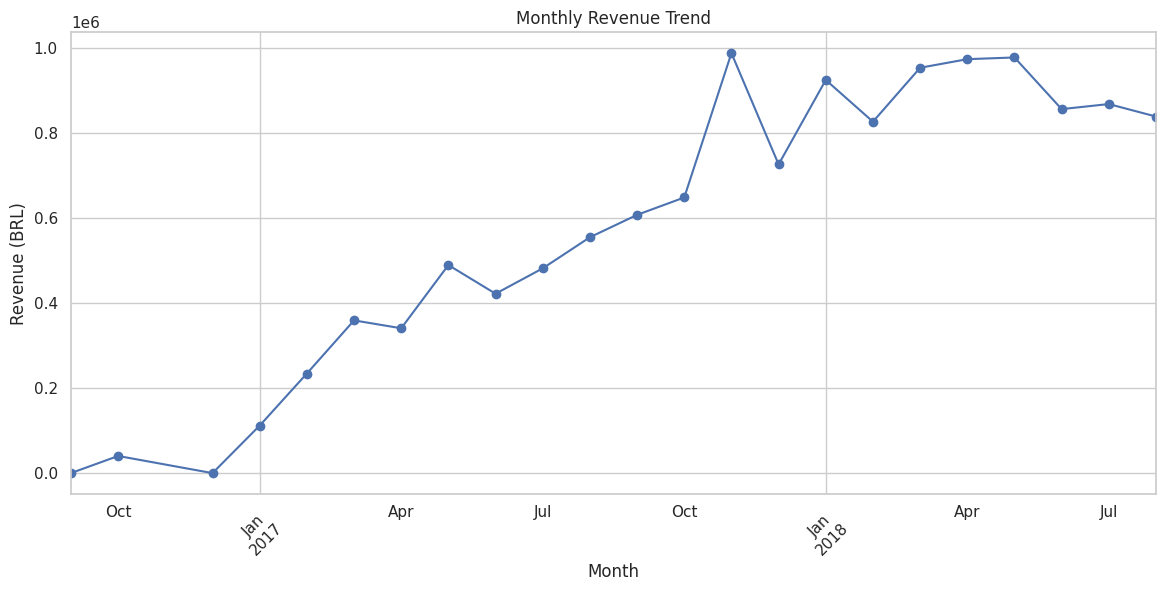

In [21]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [22]:

# Merge sales dataset with products

sales_df = sales_df.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Check the result
print("Product categories merged successfully!")

display(
    sales_df[[
        "product_id",
        "product_category_name",
        "price"
    ]].head()
)


Product categories merged successfully!


,product_id,product_category_name,price
0,87285b34884572647811a353c7ac498a,utilidades_domesticas,29.99
1,595fac2a385ac33a80bd5114aec74eb8,perfumaria,118.70
2,aa4383b373c6aca5d8797843e5594415,automotivo,159.90
3,d0b61bfb1de832b15ba9d266ca96e5b0,pet_shop,45.00
4,65266b2da20d04dbe00c5c2d3bb7859e,papelaria,19.90


In [23]:

# Calculate revenue by product category

category_revenue = (
    sales_df.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 categories
top_10_categories = category_revenue.head(10)

display(top_10_categories)


,price
product_category_name,
beleza_saude,1233131.72
relogios_presentes,1166176.98
cama_mesa_banho,1023434.76
esporte_lazer,954852.55
informatica_acessorios,888724.61
moveis_decoracao,711927.69
utilidades_domesticas,615628.69
cool_stuff,610204.10
automotivo,578966.65


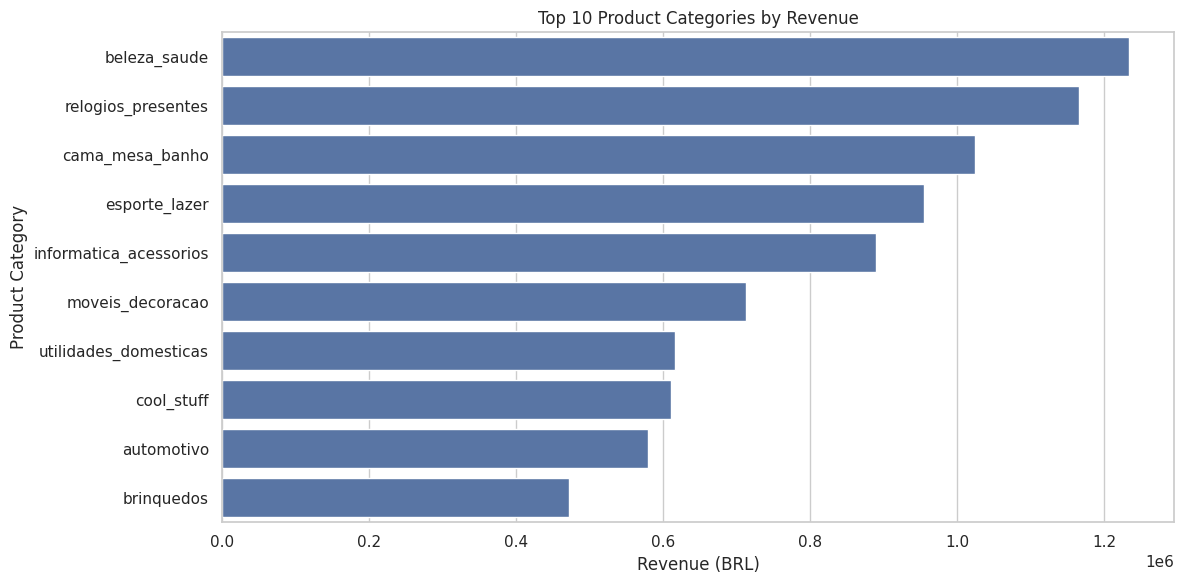

In [24]:

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")
plt.tight_layout()

plt.show()


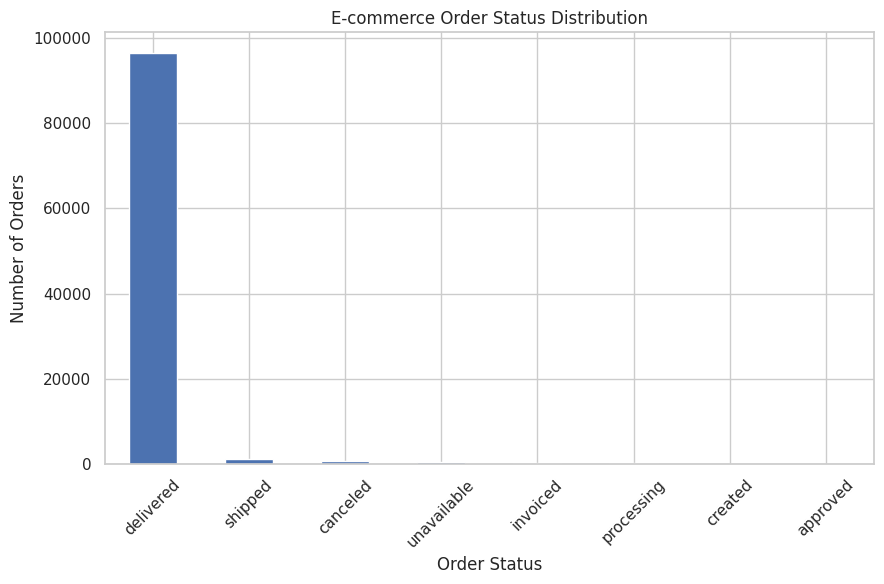

In [25]:

status_counts = orders["order_status"].value_counts()

plt.figure(figsize=(9, 6))

status_counts.plot(
    kind="bar",
    title="E-commerce Order Status Distribution"
)

plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [26]:
# Merge customer information with sales data

sales_df = sales_df.merge(
    customers[[
        "customer_id",
        "customer_unique_id",
        "customer_city",
        "customer_state"
    ]],
    on="customer_id",
    how="left"
)

print("Customer information merged successfully!")

display(sales_df.head())

Customer information merged successfully!


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,year_month,product_category_name,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,2017-10,utilidades_domesticas,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,2018-07,perfumaria,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,2018-08,automotivo,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,2017-11,pet_shop,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,2018-02,papelaria,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP


In [27]:
state_revenue = (
    sales_df.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
)

display(state_revenue.head(10))

,price
customer_state,
SP,5067633.16
RJ,1759651.13
MG,1552481.83
RS,728897.47
PR,666063.51
SC,507012.13
BA,493584.14
DF,296498.41
GO,282836.70


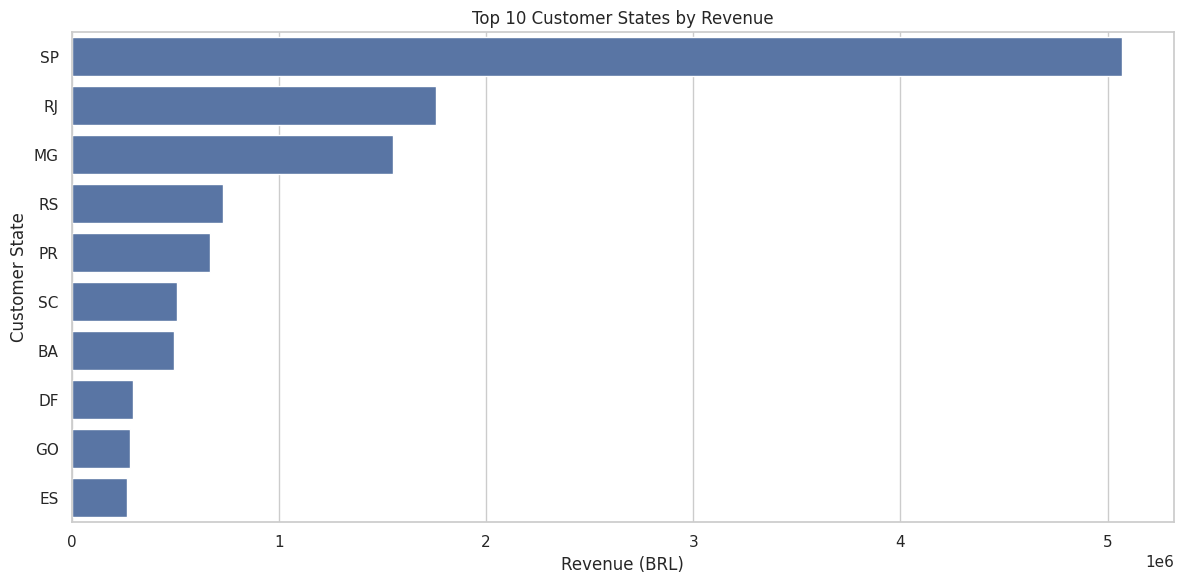

In [28]:
top_10_states = state_revenue.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_states.values,
    y=top_10_states.index
)

plt.title("Top 10 Customer States by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Customer State")

plt.tight_layout()
plt.show()

In [29]:
total_customers = sales_df["customer_unique_id"].nunique()

orders_per_customer = (
    sales_df.groupby("customer_unique_id")["order_id"]
    .nunique()
)

average_orders_per_customer = orders_per_customer.mean()

print("Total Unique Customers:", total_customers)
print("Average Orders per Customer:", round(average_orders_per_customer, 2))

Total Unique Customers: 93358
Average Orders per Customer: 1.03


In [30]:

# Review score distribution

review_distribution = reviews["review_score"].value_counts().sort_index()

print("Customer Review Distribution:")
display(review_distribution)


Customer Review Distribution:


,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [31]:

# Calculate average review score

average_rating = reviews["review_score"].mean()

print("Average Customer Rating:", round(average_rating, 2), "/ 5")

# Calculate total reviews
print("Total Reviews:", len(reviews))


Average Customer Rating: 4.09 / 5
Total Reviews: 99224


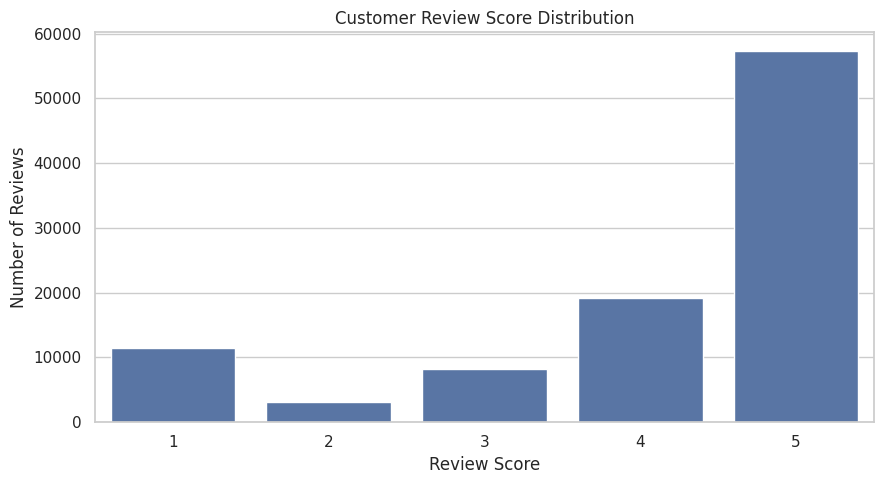

In [32]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=reviews,
    x="review_score"
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


In [33]:

# Group review scores into satisfaction categories

def categorize_review(score):
    if score >= 4:
        return "Positive"
    elif score == 3:
        return "Neutral"
    else:
        return "Negative"

reviews["satisfaction"] = reviews["review_score"].apply(
    categorize_review
)

satisfaction_counts = reviews["satisfaction"].value_counts()

display(satisfaction_counts)

# Calculate percentages
satisfaction_percentage = (
    satisfaction_counts / len(reviews) * 100
)

display(satisfaction_percentage.round(2))


,count
satisfaction,
Positive,76470
Negative,14575
Neutral,8179


,count
satisfaction,
Positive,77.07
Negative,14.69
Neutral,8.24


In [39]:

# Export analysis datasets

sales_df.to_csv("ecommerce_sales_cleaned.csv", index=False)

monthly_revenue.to_csv("monthly_revenue.csv")

top_10_categories.to_csv("top_10_categories.csv")

state_revenue.to_csv("state_revenue.csv")

review_distribution.to_csv("review_distribution.csv")

satisfaction_counts.to_csv("customer_satisfaction.csv")

print("All analysis files exported successfully!")


All analysis files exported successfully!
